# Лабораторная работа №2. Логистическая и линейная регрессия

Датасет тот же, что в лабе 1: [Anime Dataset 2023](https://www.kaggle.com/datasets/dbdmobile/myanimelist-dataset) (данные примерно о 25 тыс. аниме с MyAnimeList). Задачи тоже те же:
- классификация: предсказание возрастного рейтинга тайтла (G, PG, PG-13, R, R+), модель - логистическая регрессия
- регрессия: предсказание оценки тайтла (Score), модель - линейная регрессия

Выбор датасета и метрик обоснован в лабе 1, здесь повторяю пункты 2-4. Метрики такие же: для классификации основная macro-F1 и еще accuracy, для регрессии основная MAE и еще RMSE и R2. Разбиение на train и test тоже такое же, чтобы результаты можно было сравнивать между лабами.

Импорт библиотек.

In [1]:
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, root_mean_squared_error, r2_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Подготовка данных

Загрузка и подготовка как в лабе 1: UNKNOWN заменяю на NaN, числовые колонки перевожу в числа, в рейтинге оставляю короткие обозначения. Rank и Popularity не использую (Rank - это утечка оценки, Popularity повторяет Members). Для классификации убираю класс Rx (он совпадает с жанром Hentai) и тайтлы без рейтинга, для регрессии беру тайтлы с оценкой.

In [2]:
path = kagglehub.dataset_download("dbdmobile/myanimelist-dataset", path="anime-dataset-2023.csv")
df = pd.read_csv(path)
df = df.replace("UNKNOWN", np.nan)
for col in ["Score", "Episodes", "Rank", "Popularity", "Favorites", "Scored By", "Members"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Rating"] = df["Rating"].str.split(" - ").str[0]

df_clf = df[df["Rating"].notna() & (df["Rating"] != "Rx")].copy()
df_clf["target"] = df_clf["Rating"]
df_reg = df[df["Score"].notna()].copy()

print("Классификация:", df_clf.shape)
print("Регрессия:", df_reg.shape)

Классификация: (22761, 25)
Регрессия: (15692, 24)


Разбиение на train и test с тем же random_state, что в лабе 1 (80/20, для классификации со стратификацией).

In [3]:
idx_train_clf, idx_test_clf = train_test_split(df_clf.index, test_size=0.2, stratify=df_clf["target"],
                                               random_state=RANDOM_STATE)
idx_train_reg, idx_test_reg = train_test_split(df_reg.index, test_size=0.2, random_state=RANDOM_STATE)

y_train_clf, y_test_clf = df_clf.loc[idx_train_clf, "target"], df_clf.loc[idx_test_clf, "target"]
y_train_reg, y_test_reg = df_reg.loc[idx_train_reg, "Score"], df_reg.loc[idx_test_reg, "Score"]

print("Классификация: train", len(idx_train_clf), "test", len(idx_test_clf))
print("Регрессия: train", len(idx_train_reg), "test", len(idx_test_reg))

Классификация: train 18208 test 4553
Регрессия: train 12553 test 3139


Функции для подсчета метрик, результаты всех моделей складываю в словари.

In [4]:
def clf_metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, average="macro")}


def reg_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


results_clf = {}
results_reg = {}

## 2. Бейзлайн

Бейзлайн - LogisticRegression и LinearRegression из sklearn с параметрами по умолчанию. Признаки как в бейзлайне лабы 1: только изначально числовые колонки (Episodes, Members, Favorites, Scored By, для классификации еще Score), пропуски заполняю медианой. Заодно замеряю время обучения, чтобы потом сравнить со своей реализацией.

In [5]:
base_features_clf = ["Score", "Episodes", "Members", "Favorites", "Scored By"]
base_features_reg = ["Episodes", "Members", "Favorites", "Scored By"]

start = time.time()
baseline_clf = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression())
baseline_clf.fit(df.loc[idx_train_clf, base_features_clf], y_train_clf)
time_base_clf = time.time() - start

start = time.time()
baseline_reg = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
baseline_reg.fit(df.loc[idx_train_reg, base_features_reg], y_train_reg)
time_base_reg = time.time() - start

/Users/somarov/MAI/ai_lab/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Качество бейзлайна на тесте:

In [6]:
pred_base_clf = baseline_clf.predict(df.loc[idx_test_clf, base_features_clf])
pred_base_reg = baseline_reg.predict(df.loc[idx_test_reg, base_features_reg])

results_clf["sklearn бейзлайн"] = clf_metrics(y_test_clf, pred_base_clf)
results_reg["sklearn бейзлайн"] = reg_metrics(y_test_reg, pred_base_reg)

display(pd.DataFrame(results_clf).T.round(4))
display(pd.DataFrame(results_reg).T.round(4))

,accuracy,f1_macro
sklearn бейзлайн,0.4434,0.2226


,MAE,RMSE,R2
sklearn бейзлайн,0.6591,0.8221,0.205


Метрики по классам и какие классы модель вообще предсказывает:

In [7]:
print(classification_report(y_test_clf, pred_base_clf, digits=3, zero_division=0))
print(pd.Series(pred_base_clf).value_counts())

              precision    recall  f1-score   support

           G      0.200     0.001     0.001      1532
          PG      0.358     0.753     0.485       810
       PG-13      0.495     0.827     0.620      1701
           R      1.000     0.004     0.007       283
          R+      0.000     0.000     0.000       227

    accuracy                          0.443      4553
   macro avg      0.411     0.317     0.223      4553
weighted avg      0.378     0.443     0.319      4553

PG-13    2841
PG       1706
G           5
R           1
Name: count, dtype: int64


Бейзлайн очень слабый. sklearn предупредил, что логистическая регрессия не сошлась за 100 итераций, и в итоге модель почти всегда предсказывает PG-13 или PG (4547 из 4553 тестовых тайтлов), а G, R и R+ практически не предсказывает. Отсюда accuracy 0.443 и macro-F1 всего 0.223. Линейная регрессия тоже плохая: MAE 0.659 балла и R2 = 0.205, то есть она объясняет только 20% разброса оценок. Это хуже бейзлайна KNN в лабе 1 (там было 0.399 и 0.519), потому что оценка зависит от сырых числовых признаков сильно нелинейно.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

1. H1. Масштабирование признаков. Для логистической регрессии это важно: lbfgs плохо сходится, когда признаки в разных масштабах (Members до миллионов, Score до 10), и регуляризация штрафует коэффициенты неравномерно. Для обычной линейной регрессии (МНК без регуляризации) масштабирование не должно ничего менять, проверю это.
2. H2. Логарифмирование Members, Favorites, Scored By и Episodes. Линейная модель описывает только линейную зависимость, а связь оценки с числом зрителей явно нелинейная. После логарифма она должна стать ближе к линейной.
3. H3. Признаки из категориальных и текстовых колонок, как в лабе 1: жанры, тип, первоисточник (one-hot), длительность серии в минутах и год выхода. Для регрессии еще возрастной рейтинг.
4. H4. Относительные признаки fav_rate = Favorites / Members и scored_rate = Scored By / Members.
5. H5. Топ-20 студий (one-hot). В лабе 1 для KNN студии помогли только классификации, для линейных моделей проверю заново.
6. H6. Квадраты числовых признаков. Зависимость оценки от года и длительности нелинейная (графики ниже), а с квадратами линейная модель сможет учесть изгиб.
7. H7. Балансировка классов (class_weight="balanced"), чтобы модель чаще предсказывала редкие R и R+. Только для классификации.
8. H8. Регуляризация. Числовые признаки сильно коррелируют между собой (график ниже), из-за этого коэффициенты могут быть неустойчивыми. Для логистической регрессии подбираю силу L2-регуляризации C, для линейной пробую Ridge (L2) и Lasso (L1) с подбором alpha.

Проверяю гипотезы по очереди кросс-валидацией на train (5 фолдов). Если основная метрика улучшилась, оставляю гипотезу и следующую проверяю вместе с ней.

### 3.2. Новые признаки и визуализация

Создаю те же новые признаки, что в лабе 1.

In [8]:
def duration_to_min(s):
    if pd.isna(s):
        return np.nan
    hours = re.search(r"(\d+) hr", s)
    minutes = re.search(r"(\d+) min", s)
    seconds = re.search(r"(\d+) sec", s)
    total = 0
    if hours:
        total += int(hours.group(1)) * 60
    if minutes:
        total += int(minutes.group(1))
    if seconds:
        total += int(seconds.group(1)) / 60
    return total if total > 0 else np.nan


for col in ["Episodes", "Members", "Favorites", "Scored By"]:
    df["log_" + col] = np.log1p(df[col])

df["duration_min"] = df["Duration"].apply(duration_to_min)
df["year"] = df["Aired"].str.extract(r"(\d{4})")[0].astype(float)
df["fav_rate"] = df["Favorites"] / df["Members"].replace(0, np.nan)
df["scored_rate"] = df["Scored By"] / df["Members"].replace(0, np.nan)

genres = df["Genres"].str.get_dummies(sep=", ").add_prefix("genre_")
types = pd.get_dummies(df["Type"], prefix="type", dtype=int)
sources = pd.get_dummies(df["Source"], prefix="source", dtype=int)
ratings = pd.get_dummies(df["Rating"], prefix="rating", dtype=int)

main_studio = df["Studios"].str.split(", ").str[0]
top_studios = main_studio.value_counts().head(20).index
studios = pd.get_dummies(main_studio.where(main_studio.isin(top_studios)), prefix="studio", dtype=int)

df = pd.concat([df, genres, types, sources, ratings, studios], axis=1)

genre_cols, type_cols, source_cols = list(genres.columns), list(types.columns), list(sources.columns)
rating_cols, studio_cols = list(ratings.columns), list(studios.columns)
print("жанров:", len(genre_cols), "типов:", len(type_cols), "источников:", len(source_cols),
      "рейтингов:", len(rating_cols), "студий:", len(studio_cols))

жанров: 21 типов: 6 источников: 17 рейтингов: 6 студий: 20


Оценка в зависимости от Members до и после логарифма (к гипотезе H2):

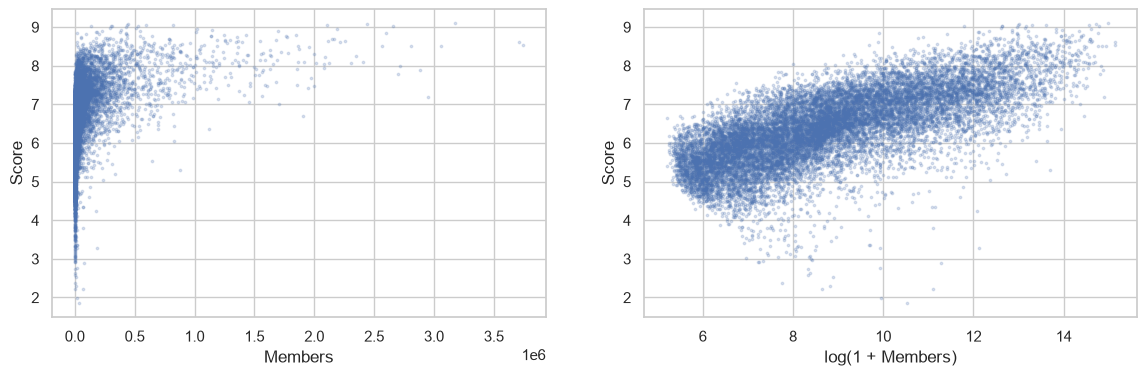

корреляция со Score: Members 0.391 log_Members 0.707


In [9]:
reg_part = df.loc[df_reg.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(reg_part["Members"], reg_part["Score"], s=3, alpha=0.2)
axes[0].set_xlabel("Members")
axes[0].set_ylabel("Score")
axes[1].scatter(reg_part["log_Members"], reg_part["Score"], s=3, alpha=0.2)
axes[1].set_xlabel("log(1 + Members)")
axes[1].set_ylabel("Score")
plt.show()

print("корреляция со Score: Members", round(reg_part["Members"].corr(reg_part["Score"]), 3),
      "log_Members", round(reg_part["log_Members"].corr(reg_part["Score"]), 3))

Слева почти все точки прижаты к левому краю, а справа видна примерно линейная зависимость: чем больше зрителей, тем выше оценка. Корреляция со Score выросла с 0.391 до 0.707, значит, для линейной модели логарифм должен сильно помочь.

Средняя оценка по десятилетиям и по длительности серии (к гипотезе H6):

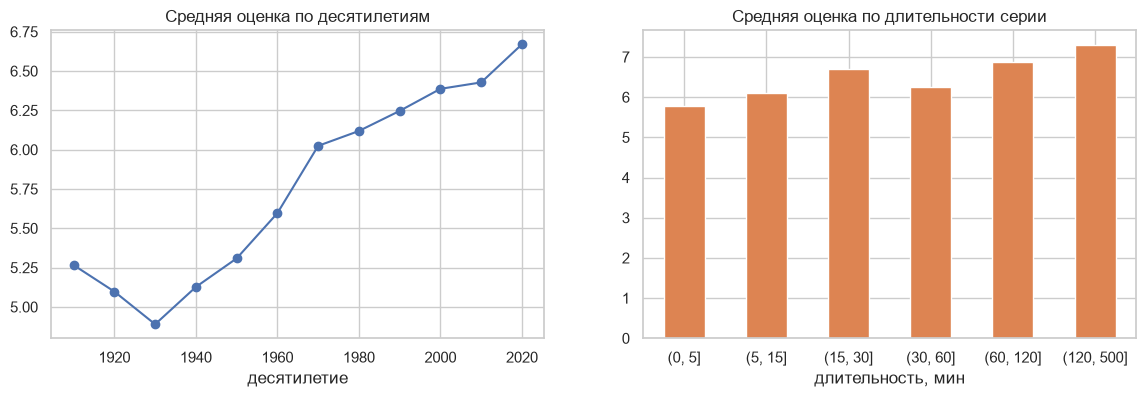

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
reg_part.groupby(reg_part["year"] // 10 * 10)["Score"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Средняя оценка по десятилетиям")
axes[0].set_xlabel("десятилетие")
duration_bins = pd.cut(reg_part["duration_min"], [0, 5, 15, 30, 60, 120, 500])
reg_part.groupby(duration_bins, observed=True)["Score"].mean().plot.bar(ax=axes[1], rot=0, color="C1")
axes[1].set_title("Средняя оценка по длительности серии")
axes[1].set_xlabel("длительность, мин")
plt.show()

Обе зависимости нелинейные. По годам средняя оценка сначала падает (минимум в 1930-х, около 4.9), а потом почти все время растет до 6.67 в 2020-х. По длительности тоже нет прямой: у серий 15-30 минут оценка выше, чем у серий 30-60 минут, а выше всего у фильмов дольше двух часов (7.3). Квадраты признаков помогут линейной модели хотя бы частично учесть такие изгибы.

Корреляции числовых признаков между собой (к гипотезе H8):

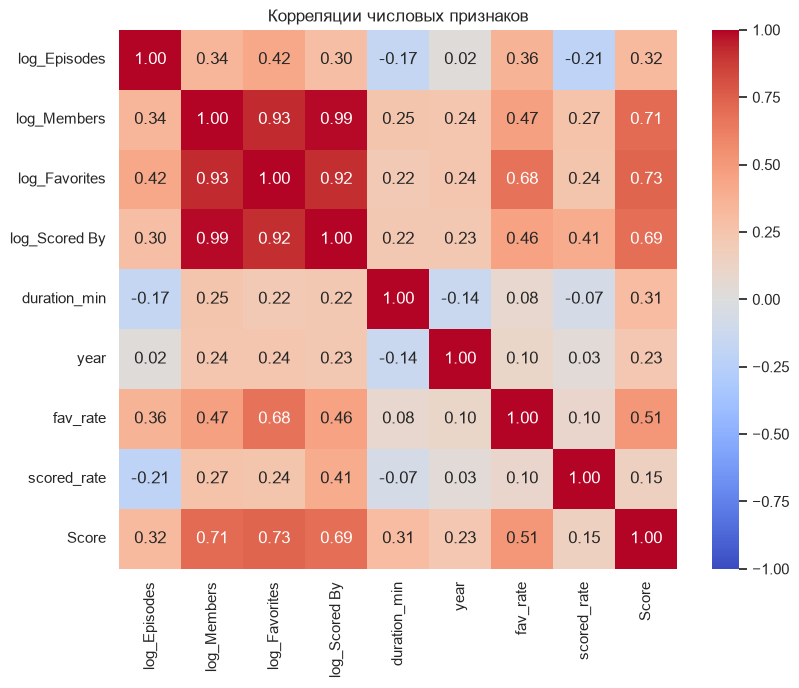

In [11]:
num_features = ["log_Episodes", "log_Members", "log_Favorites", "log_Scored By", "duration_min", "year",
                "fav_rate", "scored_rate"]

plt.figure(figsize=(9, 7))
sns.heatmap(reg_part[num_features + ["Score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции числовых признаков")
plt.show()

log_Members, log_Favorites и log_Scored By очень сильно коррелируют между собой (log_Members и log_Scored By на 0.99, с log_Favorites около 0.93). Это мультиколлинеарность: модели почти все равно, на какой из этих признаков опираться, и коэффициенты могут получаться большими и с разными знаками. Регуляризация (H8) должна с этим помочь.

### 3.3. Проверка гипотез

Функции для проверки гипотез кросс-валидацией на train (5 фолдов). Пайплайн: заполнение пропусков медианой, масштабирование (если нужно) и модель. Предупреждения о сходимости дальше отключаю, чтобы они не засоряли вывод (что бейзлайн не сходится, видно выше), а сходимость проверяю отдельно там, где это важно.

In [12]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_linear_pipeline(model, scale=True):
    steps = [SimpleImputer(strategy="median")]
    if scale:
        steps.append(StandardScaler())
    steps.append(model)
    return make_pipeline(*steps)


def check_clf(features, scale=True, C=1.0, class_weight=None, max_iter=2000):
    model = make_linear_pipeline(LogisticRegression(C=C, class_weight=class_weight, max_iter=max_iter), scale)
    scores = cross_validate(model, df.loc[idx_train_clf, features], y_train_clf, cv=cv_clf,
                            scoring=["f1_macro", "accuracy"], n_jobs=-1)
    res = {"f1_macro": scores["test_f1_macro"].mean(),
           "f1_std": scores["test_f1_macro"].std(),
           "accuracy": scores["test_accuracy"].mean()}
    print(f"Классификация ({len(features)} признаков): "
          f"macro-F1 = {res['f1_macro']:.4f} +/- {res['f1_std']:.4f}, accuracy = {res['accuracy']:.4f}")
    return res


def check_reg(features, scale=True, model=None):
    if model is None:
        model = LinearRegression()
    scores = cross_validate(make_linear_pipeline(model, scale), df.loc[idx_train_reg, features], y_train_reg,
                            cv=cv_reg, scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
                            n_jobs=-1)
    res = {"MAE": -scores["test_neg_mean_absolute_error"].mean(),
           "MAE_std": scores["test_neg_mean_absolute_error"].std(),
           "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
           "R2": scores["test_r2"].mean()}
    print(f"Регрессия ({len(features)} признаков): "
          f"MAE = {res['MAE']:.4f} +/- {res['MAE_std']:.4f}, RMSE = {res['RMSE']:.4f}, R2 = {res['R2']:.4f}")
    return res


cv_history_clf = {}
cv_history_reg = {}

Для сравнения сначала бейзлайн на кросс-валидации (с теми же параметрами по умолчанию, max_iter=100).

In [13]:
cv_history_clf["бейзлайн"] = check_clf(base_features_clf, scale=False, max_iter=100)
cv_history_reg["бейзлайн"] = check_reg(base_features_reg, scale=False)

Классификация (5 признаков): macro-F1 = 0.2219 +/- 0.0017, accuracy = 0.4409


Регрессия (4 признаков): MAE = 0.6584 +/- 0.0059, RMSE = 0.8219, R2 = 0.2191


На кросс-валидации бейзлайн дает примерно то же, что на тесте: macro-F1 0.222 и MAE 0.658.

#### H1. Масштабирование

Сначала проверяю сходимость: обучаю логистическую регрессию с max_iter=2000 без масштабирования и с ним и смотрю, сколько итераций понадобилось lbfgs. Дальше во всех проверках max_iter=2000.

In [14]:
features_clf = base_features_clf
features_reg = base_features_reg

for scale in [False, True]:
    model = make_linear_pipeline(LogisticRegression(max_iter=2000), scale)
    model.fit(df.loc[idx_train_clf, features_clf], y_train_clf)
    print("масштабирование:", scale, "| итераций lbfgs:", model[-1].n_iter_[0], "из 2000")

cv_history_clf["H1"] = check_clf(features_clf)
cv_history_reg["H1"] = check_reg(features_reg)

масштабирование: False | итераций lbfgs: 2000 из 2000
масштабирование: True | итераций lbfgs: 123 из 2000


Классификация (5 признаков): macro-F1 = 0.3080 +/- 0.0113, accuracy = 0.5343


Регрессия (4 признаков): MAE = 0.6584 +/- 0.0059, RMSE = 0.8219, R2 = 0.2191


Без масштабирования lbfgs не сходится даже за 2000 итераций (доходит до лимита), а с масштабированием сходится за 123 итерации. macro-F1 выросла с 0.222 до 0.308, accuracy с 0.441 до 0.534. Для линейной регрессии метрики не изменились вообще (MAE 0.658, R2 0.219), как и ожидалось: решение МНК не зависит от масштаба признаков, коэффициенты просто пересчитываются. H1 подтвердилась для классификации. Для регрессии масштабирование ничего не дало, но и не испортило, поэтому оставляю его: для регуляризации в H8 оно понадобится.


#### H2. Логарифмирование

In [15]:
log_features = ["log_Episodes", "log_Members", "log_Favorites", "log_Scored By"]
features_clf = ["Score"] + log_features
features_reg = log_features
cv_history_clf["H2"] = check_clf(features_clf)
cv_history_reg["H2"] = check_reg(features_reg)

Классификация (5 признаков): macro-F1 = 0.3872 +/- 0.0077, accuracy = 0.6013
Регрессия (4 признаков): MAE = 0.4842 +/- 0.0093, RMSE = 0.6304, R2 = 0.5406


Логарифм сильно помог обеим моделям, особенно линейной регрессии: MAE уменьшилась с 0.658 до 0.484, R2 вырос с 0.219 до 0.541. В классификации macro-F1 выросла с 0.308 до 0.387. H2 подтвердилась.


#### H3. Признаки из категориальных и текстовых колонок

In [16]:
new_features = ["duration_min", "year"] + genre_cols + type_cols + source_cols
features_clf = features_clf + new_features
features_reg = features_reg + new_features + rating_cols
cv_history_clf["H3"] = check_clf(features_clf)
cv_history_reg["H3"] = check_reg(features_reg)

Классификация (51 признаков): macro-F1 = 0.5699 +/- 0.0100, accuracy = 0.6604


Регрессия (56 признаков): MAE = 0.4141 +/- 0.0044, RMSE = 0.5431, R2 = 0.6591


Как и в лабе 1, самый большой прирост в классификации: macro-F1 с 0.387 до 0.570. В регрессии MAE с 0.484 до 0.414, R2 с 0.541 до 0.659. H3 подтвердилась для обеих задач.


#### H4. Относительные признаки

In [17]:
rate_features = ["fav_rate", "scored_rate"]
features_clf = features_clf + rate_features
features_reg = features_reg + rate_features
cv_history_clf["H4"] = check_clf(features_clf)
cv_history_reg["H4"] = check_reg(features_reg)

Классификация (53 признаков): macro-F1 = 0.5730 +/- 0.0105, accuracy = 0.6670


Регрессия (58 признаков): MAE = 0.4117 +/- 0.0043, RMSE = 0.5395, R2 = 0.6635


Относительные признаки дали небольшой прирост в обеих задачах: macro-F1 с 0.570 до 0.573, MAE с 0.4141 до 0.4117. Прирост маленький (меньше разброса по фолдам), но метрики стали лучше, поэтому H4 принимаю. В лабе 1 для KNN эти признаки помогли только регрессии.


#### H5. Студии

In [18]:
features_clf = features_clf + studio_cols
features_reg = features_reg + studio_cols
cv_history_clf["H5"] = check_clf(features_clf)
cv_history_reg["H5"] = check_reg(features_reg)

Классификация (73 признаков): macro-F1 = 0.5839 +/- 0.0099, accuracy = 0.6751
Регрессия (78 признаков): MAE = 0.4049 +/- 0.0048, RMSE = 0.5310, R2 = 0.6740


Студии помогли обеим задачам: macro-F1 с 0.573 до 0.584, MAE с 0.412 до 0.405. H5 подтвердилась. Это отличается от лабы 1, где для KNN студии ухудшили регрессию: в KNN 20 новых признаков портят расстояние между объектами, а линейная модель просто дает ненужным признакам маленький вес.


#### H6. Квадраты числовых признаков

In [19]:
square_base = ["Score", "log_Episodes", "log_Members", "log_Favorites", "log_Scored By", "duration_min", "year",
               "fav_rate", "scored_rate"]
for col in square_base:
    df[col + "^2"] = df[col] ** 2

squares_clf = [col + "^2" for col in square_base]
squares_reg = [col + "^2" for col in square_base if col != "Score"]
features_clf = features_clf + squares_clf
features_reg = features_reg + squares_reg
cv_history_clf["H6"] = check_clf(features_clf)
cv_history_reg["H6"] = check_reg(features_reg)

Классификация (82 признаков): macro-F1 = 0.5883 +/- 0.0097, accuracy = 0.6784
Регрессия (86 признаков): MAE = 0.3887 +/- 0.0060, RMSE = 0.5147, R2 = 0.6938


Квадраты помогли, особенно регрессии: MAE с 0.405 до 0.389, R2 с 0.674 до 0.694. В классификации macro-F1 с 0.584 до 0.588. H6 подтвердилась.


#### H7. Балансировка классов

In [20]:
cv_history_clf["H7"] = check_clf(features_clf, class_weight="balanced")

Классификация (82 признаков): macro-F1 = 0.5714 +/- 0.0077, accuracy = 0.6149


Балансировка классов ухудшила macro-F1: 0.571 против 0.588 без нее, а accuracy упала с 0.678 до 0.615. Видимо, с весами модель начинает слишком часто предсказывать R и R+ и сильно теряет точность на частых классах. H7 не подтвердилась.


#### H8. Регуляризация

Для логистической регрессии подбираю C (чем меньше C, тем сильнее регуляризация):

In [21]:
grid_clf = GridSearchCV(make_linear_pipeline(LogisticRegression(max_iter=3000)),
                        {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
                        cv=cv_clf, scoring="f1_macro", n_jobs=-1)
grid_clf.fit(df.loc[idx_train_clf, features_clf], y_train_clf)
print(grid_clf.best_params_, "macro-F1 на CV:", round(grid_clf.best_score_, 4))

{'logisticregression__C': 100} macro-F1 на CV: 0.5898


Для линейной регрессии пробую Ridge и Lasso:

In [22]:
grid_ridge = GridSearchCV(make_linear_pipeline(Ridge()),
                          {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                          cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
grid_ridge.fit(df.loc[idx_train_reg, features_reg], y_train_reg)
print("Ridge:", grid_ridge.best_params_, "MAE на CV:", round(-grid_ridge.best_score_, 4))

grid_lasso = GridSearchCV(make_linear_pipeline(Lasso(max_iter=20000)),
                          {"lasso__alpha": [0.0001, 0.001, 0.01, 0.1]},
                          cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
grid_lasso.fit(df.loc[idx_train_reg, features_reg], y_train_reg)
print("Lasso:", grid_lasso.best_params_, "MAE на CV:", round(-grid_lasso.best_score_, 4))

Ridge: {'ridge__alpha': 0.1} MAE на CV: 0.3886


Lasso: {'lasso__alpha': 0.0001} MAE на CV: 0.3887


Как качество зависит от силы регуляризации:

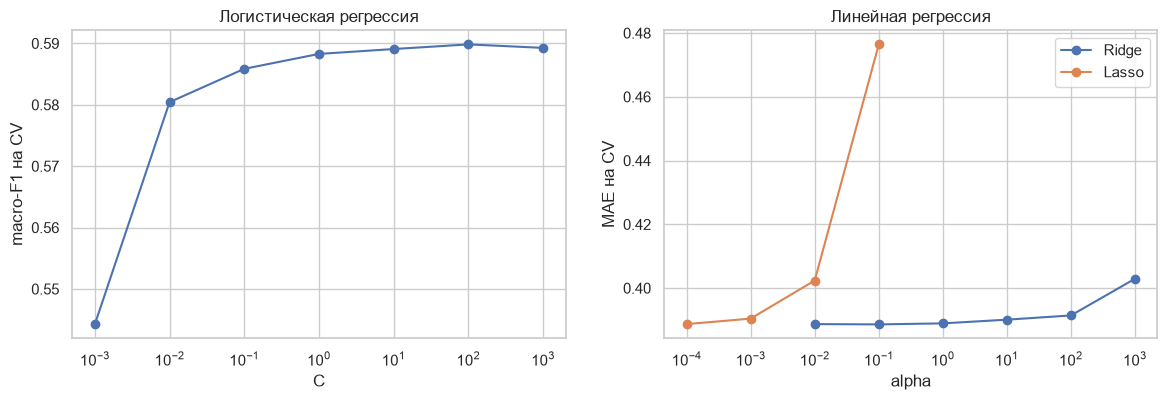

{0.001: 0.5442, 0.01: 0.5804, 0.1: 0.5859, 1.0: 0.5883, 10.0: 0.5891, 100.0: 0.5898, 1000.0: 0.5893}
Ridge: {0.01: 0.3887, 0.1: 0.3886, 1.0: 0.3889, 10.0: 0.3901, 100.0: 0.3914, 1000.0: 0.4029}
Lasso: {0.0001: 0.3887, 0.001: 0.3904, 0.01: 0.4024, 0.1: 0.4764}


In [23]:
res_c = pd.DataFrame(grid_clf.cv_results_)
res_ridge = pd.DataFrame(grid_ridge.cv_results_)
res_lasso = pd.DataFrame(grid_lasso.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(res_c["param_logisticregression__C"].astype(float), res_c["mean_test_score"], marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("C")
axes[0].set_ylabel("macro-F1 на CV")
axes[0].set_title("Логистическая регрессия")
axes[1].plot(res_ridge["param_ridge__alpha"].astype(float), -res_ridge["mean_test_score"], marker="o", label="Ridge")
axes[1].plot(res_lasso["param_lasso__alpha"].astype(float), -res_lasso["mean_test_score"], marker="o", label="Lasso")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("MAE на CV")
axes[1].set_title("Линейная регрессия")
axes[1].legend()
plt.show()

print(dict(zip(res_c["param_logisticregression__C"].astype(float), res_c["mean_test_score"].round(4))))
print("Ridge:", dict(zip(res_ridge["param_ridge__alpha"].astype(float), (-res_ridge["mean_test_score"]).round(4))))
print("Lasso:", dict(zip(res_lasso["param_lasso__alpha"].astype(float), (-res_lasso["mean_test_score"]).round(4))))

Пересчитываю все метрики на кросс-валидации для лучших параметров:

In [24]:
best_C = grid_clf.best_params_["logisticregression__C"]
best_alpha = grid_ridge.best_params_["ridge__alpha"]

cv_history_clf["H8"] = check_clf(features_clf, C=best_C)
cv_history_reg["H8"] = check_reg(features_reg, model=Ridge(alpha=best_alpha))

Классификация (82 признаков): macro-F1 = 0.5898 +/- 0.0076, accuracy = 0.6802
Регрессия (86 признаков): MAE = 0.3886 +/- 0.0060, RMSE = 0.5147, R2 = 0.6937


Для логистической регрессии лучшее C=100, то есть регуляризация почти не нужна: macro-F1 выросла совсем немного, с 0.588 до 0.590. При сильной регуляризации (C=0.001) качество заметно падает (0.544), а при C от 1 до 1000 почти не меняется. Для линейной регрессии лучший вариант Ridge с alpha=0.1: MAE 0.3886 против 0.3887 без регуляризации. Lasso лучше не стал (0.3887 при самом маленьком alpha), а с ростом alpha обе модели только ухудшаются. Регуляризация почти ничего не дает, потому что объектов (12-18 тысяч) намного больше, чем признаков (80-90), и модели не переобучаются. Формально метрики немного улучшились, поэтому H8 принимаю: C=100 и Ridge с alpha=0.1.


Как менялась основная метрика по гипотезам (серым - гипотезы, которые не дали улучшения):

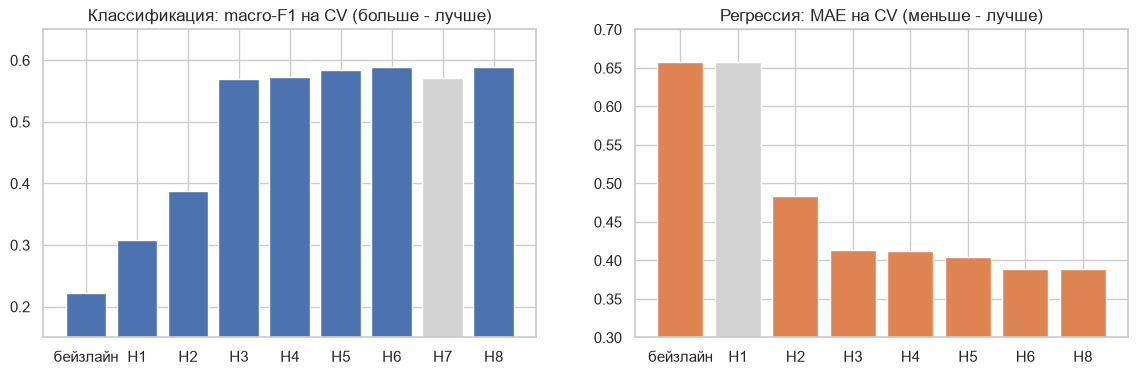

In [25]:
steps_clf = ["бейзлайн", "H1", "H2", "H3", "H4", "H5", "H6", "H7", "H8"]
steps_reg = ["бейзлайн", "H1", "H2", "H3", "H4", "H5", "H6", "H8"]
rejected_clf = ["H7"]
rejected_reg = ["H1"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(steps_clf, [cv_history_clf[s]["f1_macro"] for s in steps_clf],
            color=["lightgray" if s in rejected_clf else "C0" for s in steps_clf])
axes[0].set_ylim(0.15, 0.65)
axes[0].set_title("Классификация: macro-F1 на CV (больше - лучше)")
axes[1].bar(steps_reg, [cv_history_reg[s]["MAE"] for s in steps_reg],
            color=["lightgray" if s in rejected_reg else "C1" for s in steps_reg])
axes[1].set_ylim(0.3, 0.7)
axes[1].set_title("Регрессия: MAE на CV (меньше - лучше)")
plt.show()

### 3.4. Улучшенный бейзлайн

По итогам проверки гипотез улучшенный бейзлайн получился такой:
- классификация: масштабирование (H1), логарифмы (H2), жанры, тип, первоисточник, длительность и год (H3), относительные признаки (H4), топ-20 студий (H5), квадраты числовых признаков (H6), логистическая регрессия с C=100 (H8), всего 82 признака
- регрессия: те же шаги H1-H6 и еще возрастной рейтинг как признак, Ridge с alpha=0.1 (H8), всего 86 признаков

GridSearchCV уже обучил лучшие модели на всем train, проверяю их на тесте.

In [26]:
improved_clf = grid_clf.best_estimator_
improved_reg = grid_ridge.best_estimator_

pred_impr_clf = improved_clf.predict(df.loc[idx_test_clf, features_clf])
pred_impr_reg = improved_reg.predict(df.loc[idx_test_reg, features_reg])

results_clf["sklearn улучшенный"] = clf_metrics(y_test_clf, pred_impr_clf)
results_reg["sklearn улучшенный"] = reg_metrics(y_test_reg, pred_impr_reg)

print(classification_report(y_test_clf, pred_impr_clf, digits=3))

              precision    recall  f1-score   support

           G      0.672     0.755     0.711      1532
          PG      0.727     0.690     0.708       810
       PG-13      0.688     0.724     0.706      1701
           R      0.622     0.279     0.385       283
          R+      0.585     0.379     0.460       227

    accuracy                          0.684      4553
   macro avg      0.659     0.565     0.594      4553
weighted avg      0.680     0.684     0.676      4553



Матрица ошибок (по строкам доли от реального класса):

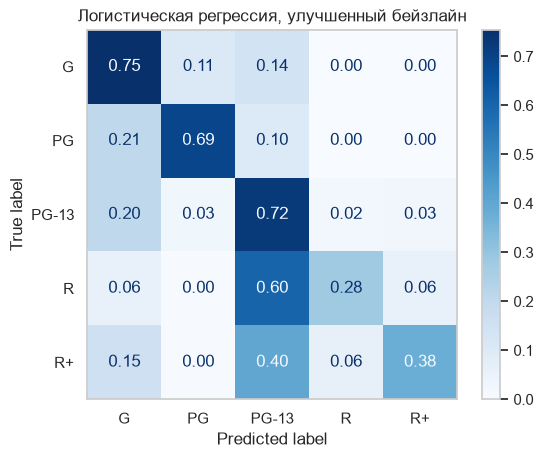

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test_clf, pred_impr_clf, labels=["G", "PG", "PG-13", "R", "R+"],
                                        normalize="true", values_format=".2f", cmap="Blues")
plt.title("Логистическая регрессия, улучшенный бейзлайн")
plt.grid(False)
plt.show()

По сравнению с бейзлайном модель теперь различает все классы, но R и R+ все равно угадываются плохо: 60% тайтлов R и 40% тайтлов R+ модель относит к PG-13 (F1 0.385 и 0.460). Взрослый тайтл получает G у 6% тайтлов R и у 15% тайтлов R+. В обратную сторону ошибок почти нет, G и PG практически не получают R или R+.

Коэффициенты улучшенной линейной регрессии (признаки масштабированы, поэтому коэффициенты можно сравнивать между собой):

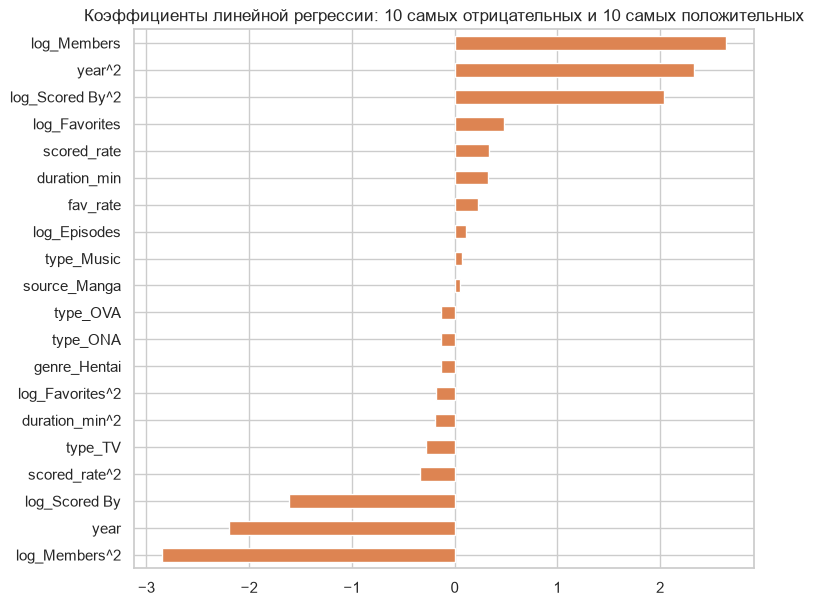

In [28]:
coefs = pd.Series(improved_reg[-1].coef_, index=features_reg).sort_values()

plt.figure(figsize=(8, 7))
pd.concat([coefs.head(10), coefs.tail(10)]).plot.barh(color="C1")
plt.title("Коэффициенты линейной регрессии: 10 самых отрицательных и 10 самых положительных")
plt.show()

Самые большие по модулю коэффициенты у пар признак и его квадрат, причем с разными знаками: log_Members и log_Members^2, year и year^2, log_Scored By и его квадрат. По отдельности такие коэффициенты интерпретировать нельзя: вместе пара задает параболу, то есть изогнутую зависимость, как на графике по десятилетиям. К тому же эти признаки сильно коррелируют между собой, а при мультиколлинеарности коэффициенты получаются большими и с разными знаками. Из остальных признаков заметный положительный вклад у log_Favorites, scored_rate, длительности серии и fav_rate.

Предсказанная оценка против реальной:

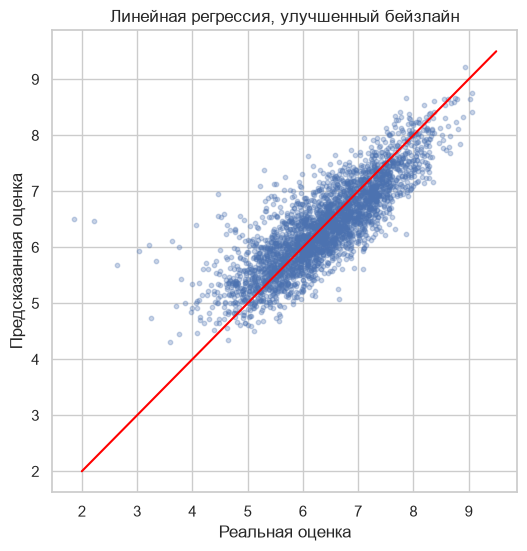

In [29]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_reg, pred_impr_reg, alpha=0.3, s=10)
plt.plot([2, 9.5], [2, 9.5], color="red")
plt.xlabel("Реальная оценка")
plt.ylabel("Предсказанная оценка")
plt.title("Линейная регрессия, улучшенный бейзлайн")
plt.show()

Точки в целом идут вдоль диагонали. Низкие оценки модель сильно завышает: для тайтлов с оценкой 2-4 она предсказывает примерно 4.3-6.5. С высокими оценками получается лучше, около 8-9 точки ближе к диагонали.

### 3.5. Сравнение с бейзлайном

Метрики на тесте и разница:

In [30]:
compare_clf = pd.DataFrame(results_clf).T
compare_reg = pd.DataFrame(results_reg).T
compare_clf.loc["изменение"] = compare_clf.loc["sklearn улучшенный"] - compare_clf.loc["sklearn бейзлайн"]
compare_reg.loc["изменение"] = compare_reg.loc["sklearn улучшенный"] - compare_reg.loc["sklearn бейзлайн"]
display(compare_clf.round(4))
display(compare_reg.round(4))

,accuracy,f1_macro
sklearn бейзлайн,0.4434,0.2226
sklearn улучшенный,0.6835,0.5940
изменение,0.2401,0.3715


,MAE,RMSE,R2
sklearn бейзлайн,0.6591,0.8221,0.2050
sklearn улучшенный,0.3806,0.5076,0.6969
изменение,-0.2785,-0.3145,0.4919


### 3.6. Выводы

- Улучшенный бейзлайн на тесте намного лучше исходного. В классификации macro-F1 выросла с 0.223 до 0.594, accuracy с 0.443 до 0.684. В регрессии MAE уменьшилась с 0.659 до 0.381, RMSE с 0.822 до 0.508, R2 вырос с 0.205 до 0.697.
- Для логистической регрессии главное - масштабирование (без него модель вообще не сходится) и признаки из категориальных колонок. Для линейной регрессии больше всего дали логарифмы и квадраты признаков, то есть приведение зависимостей к линейному виду.
- Студии и относительные признаки помогли обеим линейным моделям, хотя для KNN часть этих признаков мешала: линейная модель просто дает бесполезным признакам маленький вес.
- Балансировка классов не помогла, а регуляризация почти ничего не дала, потому что данных намного больше, чем признаков.
- Слабое место то же, что у KNN: редкие классы R и R+ часто путаются с PG-13.

## 4. Собственная реализация

### 4.1. Реализация

Линейную регрессию считаю по аналитической формуле (нормальное уравнение). К признакам добавляю столбец единиц для свободного члена. Без регуляризации решаю задачу наименьших квадратов через np.linalg.lstsq, а с L2-регуляризацией (как в Ridge) решаю систему (X^T X + alpha * I) w = X^T y, где свободный член не штрафуется.

Логистическую регрессию для нескольких классов делаю через softmax: для каждого класса свой вектор весов, вероятности считаются softmax от линейных функций, а веса обучаются градиентным спуском по кросс-энтропии. Регуляризация L2 как в sklearn: к функции потерь добавляется ||W||^2 / (2 * C * n). Каждые 100 итераций сохраняю значение logloss на train, чтобы смотреть на сходимость.

In [31]:
class MyLinearRegression:
    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        Xb = np.hstack([np.ones((len(X), 1)), X])
        if self.alpha == 0:
            w = np.linalg.lstsq(Xb, y, rcond=None)[0]
        else:
            I = np.eye(Xb.shape[1])
            I[0, 0] = 0
            w = np.linalg.solve(Xb.T @ Xb + self.alpha * I, Xb.T @ y)
        self.intercept_ = w[0]
        self.coef_ = w[1:]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_


class MyLogisticRegression:
    def __init__(self, C=1.0, lr=0.1, n_iter=1000):
        self.C = C
        self.lr = lr
        self.n_iter = n_iter

    def _softmax(self, Z):
        Z = Z - Z.max(axis=1, keepdims=True)
        E = np.exp(Z)
        return E / E.sum(axis=1, keepdims=True)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        n, d = X.shape
        self.classes_ = np.unique(y)
        Y = (y[:, None] == self.classes_).astype(float)
        self.W = np.zeros((d, len(self.classes_)))
        self.b = np.zeros(len(self.classes_))
        self.losses = []
        for i in range(self.n_iter):
            P = self._softmax(X @ self.W + self.b)
            if i % 100 == 0 or i == self.n_iter - 1:
                self.losses.append(-np.mean(np.log(P[Y == 1] + 1e-15)))
            self.W -= self.lr * (X.T @ (P - Y) / n + self.W / (self.C * n))
            self.b -= self.lr * (P - Y).mean(axis=0)
        return self

    def predict_proba(self, X):
        return self._softmax(np.asarray(X, dtype=float) @ self.W + self.b)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

### 4.2. Обучение в условиях бейзлайна

Признаки те же, что в пункте 2, пропуски заполняю медианой по train, без масштабирования. Для линейной регрессии параметров нет. Для логистической C=1, как по умолчанию в sklearn, а шаг градиентного спуска нужно выбрать: на сырых признаках (Members до миллионов) обычный шаг сразу разносит веса. Пробую несколько шагов по 1000 итераций и беру тот, у которого меньше logloss на train.

In [32]:
imputer_clf = SimpleImputer(strategy="median").fit(df.loc[idx_train_clf, base_features_clf])
X_train_base_clf = imputer_clf.transform(df.loc[idx_train_clf, base_features_clf])
X_test_base_clf = imputer_clf.transform(df.loc[idx_test_clf, base_features_clf])

imputer_reg = SimpleImputer(strategy="median").fit(df.loc[idx_train_reg, base_features_reg])
X_train_base_reg = imputer_reg.transform(df.loc[idx_train_reg, base_features_reg])
X_test_base_reg = imputer_reg.transform(df.loc[idx_test_reg, base_features_reg])

train_losses = {}
for lr in [1e-12, 1e-11, 1e-10, 1e-9, 1e-8]:
    model = MyLogisticRegression(lr=lr, n_iter=1000).fit(X_train_base_clf, y_train_clf)
    train_losses[lr] = model.losses[-1]
    print(f"шаг {lr}: logloss на train {model.losses[0]:.4f} -> {model.losses[-1]:.4f}")

best_lr = min(train_losses, key=train_losses.get)
print("выбранный шаг:", best_lr)

шаг 1e-12: logloss на train 1.6094 -> 1.5574


шаг 1e-11: logloss на train 1.6094 -> 1.5393


шаг 1e-10: logloss на train 1.6094 -> 1.5203


шаг 1e-09: logloss на train 1.6094 -> 1.7637


шаг 1e-08: logloss на train 1.6094 -> 2.1135
выбранный шаг: 1e-10


Обучаю свои модели с выбранным шагом и считаю метрики:

In [33]:
start = time.time()
my_base_clf = MyLogisticRegression(lr=best_lr, n_iter=1000).fit(X_train_base_clf, y_train_clf)
time_my_base_clf = time.time() - start
pred_my_base_clf = my_base_clf.predict(X_test_base_clf)

start = time.time()
my_base_reg = MyLinearRegression().fit(X_train_base_reg, y_train_reg)
time_my_base_reg = time.time() - start
pred_my_base_reg = my_base_reg.predict(X_test_base_reg)

results_clf["своя реализация, бейзлайн"] = clf_metrics(y_test_clf, pred_my_base_clf)
results_reg["своя реализация, бейзлайн"] = reg_metrics(y_test_reg, pred_my_base_reg)

### 4.3. Сравнение с бейзлайном sklearn (пункт 2)

In [34]:
display(pd.DataFrame(results_clf).T.loc[["sklearn бейзлайн", "своя реализация, бейзлайн"]].round(4))
display(pd.DataFrame(results_reg).T.loc[["sklearn бейзлайн", "своя реализация, бейзлайн"]].round(4))

print("Совпадение предсказаний классов:", round((pred_my_base_clf == pred_base_clf).mean(), 4))
print("Максимальная разница предсказаний регрессии:", np.abs(pred_my_base_reg - pred_base_reg).max())
print(pd.Series(pred_my_base_clf).value_counts())
print(f"Время обучения, классификация: sklearn {time_base_clf:.2f} с, своя реализация {time_my_base_clf:.2f} с")
print(f"Время обучения, регрессия: sklearn {time_base_reg * 1000:.1f} мс, своя реализация {time_my_base_reg * 1000:.1f} мс")

,accuracy,f1_macro
sklearn бейзлайн,0.4434,0.2226
"своя реализация, бейзлайн",0.4777,0.2241


,MAE,RMSE,R2
sklearn бейзлайн,0.6591,0.8221,0.205
"своя реализация, бейзлайн",0.6591,0.8221,0.205


Совпадение предсказаний классов: 0.6242
Максимальная разница предсказаний регрессии: 1.0622613899613498e-12
PG-13    2842
G        1695
R+          9
R           7
Name: count, dtype: int64
Время обучения, классификация: sklearn 0.09 с, своя реализация 0.77 с
Время обучения, регрессия: sklearn 3.9 мс, своя реализация 0.4 мс


Линейная регрессия совпала с sklearn полностью: метрики одинаковые, а разница предсказаний порядка 1e-12, то есть только погрешность вычислений. Это ожидаемо, потому что sklearn тоже решает задачу наименьших квадратов. Считается она мгновенно.

С логистической регрессией все сложнее. На сырых признаках градиентный спуск, как и lbfgs в sklearn, нормально не сходится: при маленьком шаге logloss почти не падает, а при шаге 1e-9 и больше начинает расти. С лучшим шагом 1e-10 метрики примерно как у sklearn (macro-F1 0.224 против 0.223, accuracy 0.478 против 0.443), но предсказания совпадают только у 62% тайтлов. Обе модели фактически выбирают между двумя классами: sklearn между PG-13 и PG, а моя реализация между PG-13 и G. То есть это две разные недообученные модели, которые застряли далеко от оптимума. По времени своя логистическая регрессия медленнее sklearn, но обе обучаются меньше чем за секунду.

### 4.4. Своя реализация с техниками из улучшенного бейзлайна

Беру из улучшенных пайплайнов sklearn шаги до модели (заполнение пропусков и масштабирование), они уже обучены на train, и прогоняю через них данные. Признаки те же, что в улучшенном бейзлайне. Своей линейной регрессии передаю alpha как у лучшего Ridge, логистической C из подбора. Шаг градиентного спуска на масштабированных признаках можно взять большой (1.0), итераций ставлю 6000.

In [35]:
prep_clf = improved_clf[:-1]
prep_reg = improved_reg[:-1]

X_train_impr_clf = prep_clf.transform(df.loc[idx_train_clf, features_clf])
X_test_impr_clf = prep_clf.transform(df.loc[idx_test_clf, features_clf])
X_train_impr_reg = prep_reg.transform(df.loc[idx_train_reg, features_reg])
X_test_impr_reg = prep_reg.transform(df.loc[idx_test_reg, features_reg])
print(X_train_impr_clf.shape, X_train_impr_reg.shape)

start = time.time()
my_impr_clf = MyLogisticRegression(C=best_C, lr=1.0, n_iter=6000).fit(X_train_impr_clf, y_train_clf)
time_my_impr_clf = time.time() - start
pred_my_impr_clf = my_impr_clf.predict(X_test_impr_clf)

start = time.time()
my_impr_reg = MyLinearRegression(alpha=best_alpha).fit(X_train_impr_reg, y_train_reg)
time_my_impr_reg = time.time() - start
pred_my_impr_reg = my_impr_reg.predict(X_test_impr_reg)

results_clf["своя реализация, улучшенный"] = clf_metrics(y_test_clf, pred_my_impr_clf)
results_reg["своя реализация, улучшенный"] = reg_metrics(y_test_reg, pred_my_impr_reg)

(18208, 82) (12553, 86)


Как падал logloss при обучении своей логистической регрессии:

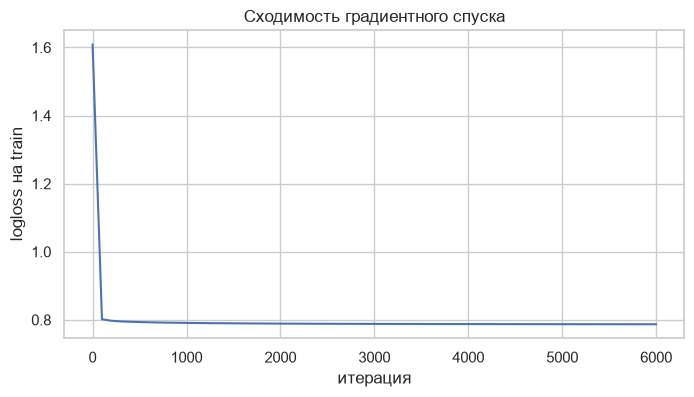

logloss в начале: 1.6094 в конце: 0.7868


In [36]:
plt.figure(figsize=(8, 4))
plt.plot(np.arange(len(my_impr_clf.losses)) * 100, my_impr_clf.losses)
plt.xlabel("итерация")
plt.ylabel("logloss на train")
plt.title("Сходимость градиентного спуска")
plt.show()

print("logloss в начале:", round(my_impr_clf.losses[0], 4), "в конце:", round(my_impr_clf.losses[-1], 4))

### 4.5. Сравнение с улучшенным бейзлайном sklearn (пункт 3)

Для сравнения времени заново обучаю улучшенные модели sklearn на train.

In [37]:
start = time.time()
improved_clf.fit(df.loc[idx_train_clf, features_clf], y_train_clf)
time_impr_clf = time.time() - start

start = time.time()
improved_reg.fit(df.loc[idx_train_reg, features_reg], y_train_reg)
time_impr_reg = time.time() - start

display(pd.DataFrame(results_clf).T.loc[["sklearn улучшенный", "своя реализация, улучшенный"]].round(4))
display(pd.DataFrame(results_reg).T.loc[["sklearn улучшенный", "своя реализация, улучшенный"]].round(4))

print("Совпадение предсказаний классов:", round((pred_my_impr_clf == pred_impr_clf).mean(), 4))
print("Максимальная разница предсказаний регрессии:", np.abs(pred_my_impr_reg - pred_impr_reg).max())
print(f"Время обучения, классификация: sklearn {time_impr_clf:.2f} с, своя реализация {time_my_impr_clf:.2f} с")
print(f"Время обучения, регрессия: sklearn {time_impr_reg * 1000:.1f} мс, своя реализация {time_my_impr_reg * 1000:.1f} мс")

,accuracy,f1_macro
sklearn улучшенный,0.6835,0.5940
"своя реализация, улучшенный",0.6828,0.5919


,MAE,RMSE,R2
sklearn улучшенный,0.3806,0.5076,0.6969
"своя реализация, улучшенный",0.3806,0.5076,0.6969


Совпадение предсказаний классов: 0.9901
Максимальная разница предсказаний регрессии: 4.6211923176997516e-12
Время обучения, классификация: sklearn 0.30 с, своя реализация 6.30 с
Время обучения, регрессия: sklearn 31.5 мс, своя реализация 0.7 мс


На масштабированных признаках своя логистическая регрессия почти совпала с sklearn: macro-F1 0.592 против 0.594, accuracy 0.683 против 0.684, предсказания совпадают у 99% тайтлов. Небольшая разница из-за того, что градиентный спуск за 6000 итераций подходит к оптимуму не до конца, а lbfgs в sklearn находит его точнее (по графику logloss видно, что в конце он уже почти не падает). Линейная регрессия с регуляризацией совпала с Ridge из sklearn полностью (разница порядка 1e-12).

По сравнению со своей реализацией на признаках бейзлайна macro-F1 выросла с 0.224 до 0.592, а MAE снизилась с 0.659 до 0.381, так же как у sklearn. То есть улучшение дают обработка признаков и масштабирование, и для градиентного спуска масштабирование особенно важно: на сырых признаках он почти не работал, а на масштабированных сходится даже с большим шагом.

По времени градиентный спуск заметно медленнее lbfgs: несколько секунд против десятых долей секунды. Аналитическая линейная регрессия, наоборот, считается очень быстро.

## 5. Итоги

Все модели на тесте. Таблицу сохраняю в lab2_results.csv для итогового сравнения в лабораторной 5.

,accuracy,f1_macro
sklearn бейзлайн,0.4434,0.2226
sklearn улучшенный,0.6835,0.5940
"своя реализация, бейзлайн",0.4777,0.2241
"своя реализация, улучшенный",0.6828,0.5919


,MAE,RMSE,R2
sklearn бейзлайн,0.6591,0.8221,0.2050
sklearn улучшенный,0.3806,0.5076,0.6969
"своя реализация, бейзлайн",0.6591,0.8221,0.2050
"своя реализация, улучшенный",0.3806,0.5076,0.6969


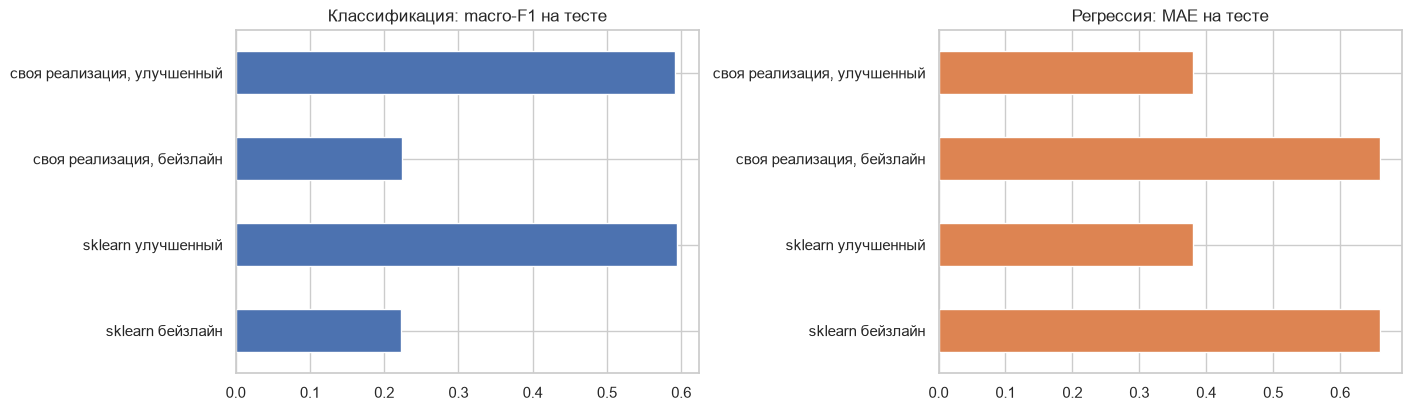

In [38]:
final_clf = pd.DataFrame(results_clf).T
final_reg = pd.DataFrame(results_reg).T
display(final_clf.round(4))
display(final_reg.round(4))

pd.concat({"классификация": final_clf, "регрессия": final_reg}).round(4).to_csv("lab2_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
final_clf["f1_macro"].plot.barh(ax=axes[0], color="C0")
axes[0].set_title("Классификация: macro-F1 на тесте")
final_reg["MAE"].plot.barh(ax=axes[1], color="C1")
axes[1].set_title("Регрессия: MAE на тесте")
plt.show()

Выводы:
- На сырых признаках линейные модели работают плохо: логистическая регрессия не сходится и предсказывает почти только два класса (macro-F1 0.223), а линейная регрессия объясняет только 20% разброса оценок (MAE 0.659).
- После обработки признаков (масштабирование, логарифмы, категориальные и относительные признаки, студии, квадраты) и подбора регуляризации качество сильно выросло: macro-F1 с 0.223 до 0.594, accuracy с 0.443 до 0.684, MAE с 0.659 до 0.381, R2 с 0.205 до 0.697.
- Своя линейная регрессия совпадает с sklearn полностью, своя логистическая регрессия на масштабированных данных почти полностью (99% предсказаний), но градиентный спуск медленнее lbfgs и сильно зависит от масштаба признаков.
- По сравнению с KNN из лабы 1 линейные модели немного хуже: у KNN macro-F1 0.634 и MAE 0.363 против 0.594 и 0.381 здесь. Зато линейные модели быстро обучаются и предсказывают.
- Результаты сохранены в lab2_results.csv для итогового сравнения в лабораторной 5.